In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

In [12]:
tile_df = pd.read_pickle(r"E1A_tile_sequences_scores.pkl").reset_index(drop=True)
e1a_full_length = pd.read_pickle(r"E1A_sequences_scores.pkl")

In [6]:
mpl.style.use('default')
mpl.rcParams['axes.linewidth'] = 7  # set the value globally
mpl.rcParams['xtick.major.size'] = 20
mpl.rcParams['xtick.major.width'] = 7
mpl.rcParams['xtick.minor.size'] = 10
mpl.rcParams['xtick.minor.width'] = 7
mpl.rcParams['ytick.major.size'] = 20
mpl.rcParams['ytick.major.width'] = 7
mpl.rcParams['ytick.labelsize'] = 50
mpl.rcParams['xtick.labelsize'] = 50
mpl.rcParams['ytick.minor.size'] = 10
mpl.rcParams['ytick.minor.width'] = 7
mpl.rcParams['font.size'] = 55
mpl.rcParams['font.sans-serif'] = 'Arial'
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['svg.fonttype'] = 'none'

In [18]:
e1a_full_length

,e1a_sequnce,start,end,sequence,UniProt_code_origin,NLS_probabilities,NES_probabilities,R_end_to_end,R_gyration,Average_disordered,std_score,disorder_array
0,ADV5,1,289,MRHIICHGGVITEEMAASLLDQLIEEVLADNLPPPSHFEPPTLHEL...,P03255,"[0.00176, 0.00401, 0.00077, 0.0, 0.0, 0.0, 0.0...","[0.00131, 0.00048, 0.00014, 8e-05, 8e-05, 6e-0...",138.375645,57.030959,0.621218,0.278473,"[0.6935, 0.6361, 0.5376, 0.4197, 0.3327, 0.287..."


In [13]:
tile_df.head()

,tile,start,end,sequence,UniProt_code_origin,NLS_probabilities,NES_probabilities,R_end_to_end,R_gyration,Average_disordered,std_score,disorder_array
0,T1,1,64,MRHIICHGGVITEEMAASLLDQLIEEVLADNLPPPSHFEPPTLHEL...,P03255,"[0.00177, 0.00397, 0.00076, 0.0, 0.0, 0.0, 0.0...","[0.00132, 0.00048, 0.00014, 8e-05, 8e-05, 7e-0...",60.796135,25.962091,0.402252,0.278378,"[0.6374, 0.5857, 0.4885, 0.3724, 0.2925, 0.261..."
1,T2,21,84,DQLIEEVLADNLPPPSHFEPPTLHELYDLDVTAPEDPNEEAVSQIF...,P03255,"[0.00034, 0.00222, 0.00049, 5e-05, 4e-05, 2e-0...","[0.02875, 0.01282, 0.0101, 0.00962, 0.01058, 0...",65.010506,25.773443,0.545578,0.107360,"[0.5726, 0.5657, 0.504, 0.4665, 0.4559, 0.4491..."
2,T3,41,104,PTLHELYDLDVTAPEDPNEEAVSQIFPDSVMLAVQEGIDLLTFPPA...,P03255,"[0.00017, 5e-05, 6e-05, 0.00012, 6e-05, 6e-05,...","[0.00176, 0.00072, 0.00057, 0.00036, 0.00034, ...",64.288742,25.958504,0.661677,0.156521,"[0.8426, 0.803, 0.7617, 0.7241, 0.6972, 0.6708..."
3,T4,61,124,AVSQIFPDSVMLAVQEGIDLLTFPPAPGSPEPPHLSRQPEQPEQRA...,P03255,"[0.00132, 0.00028, 0.00012, 0.00019, 1e-04, 4e...","[0.00118, 0.00038, 0.00016, 0.00011, 0.00016, ...",62.981426,26.045750,0.677130,0.154716,"[0.824, 0.8455, 0.7679, 0.7087, 0.6422, 0.5948..."
4,T5,81,144,LTFPPAPGSPEPPHLSRQPEQPEQRALGPVSMPNLVPEVIDLTCHE...,P03255,"[0.01125, 0.00016, 3e-05, 0.00038, 0.00074, 0....","[0.00465, 0.0019, 0.00125, 0.00095, 0.00075, 0...",62.705284,25.556606,0.796212,0.072572,"[0.8365, 0.9082, 0.8873, 0.8682, 0.8631, 0.867..."


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


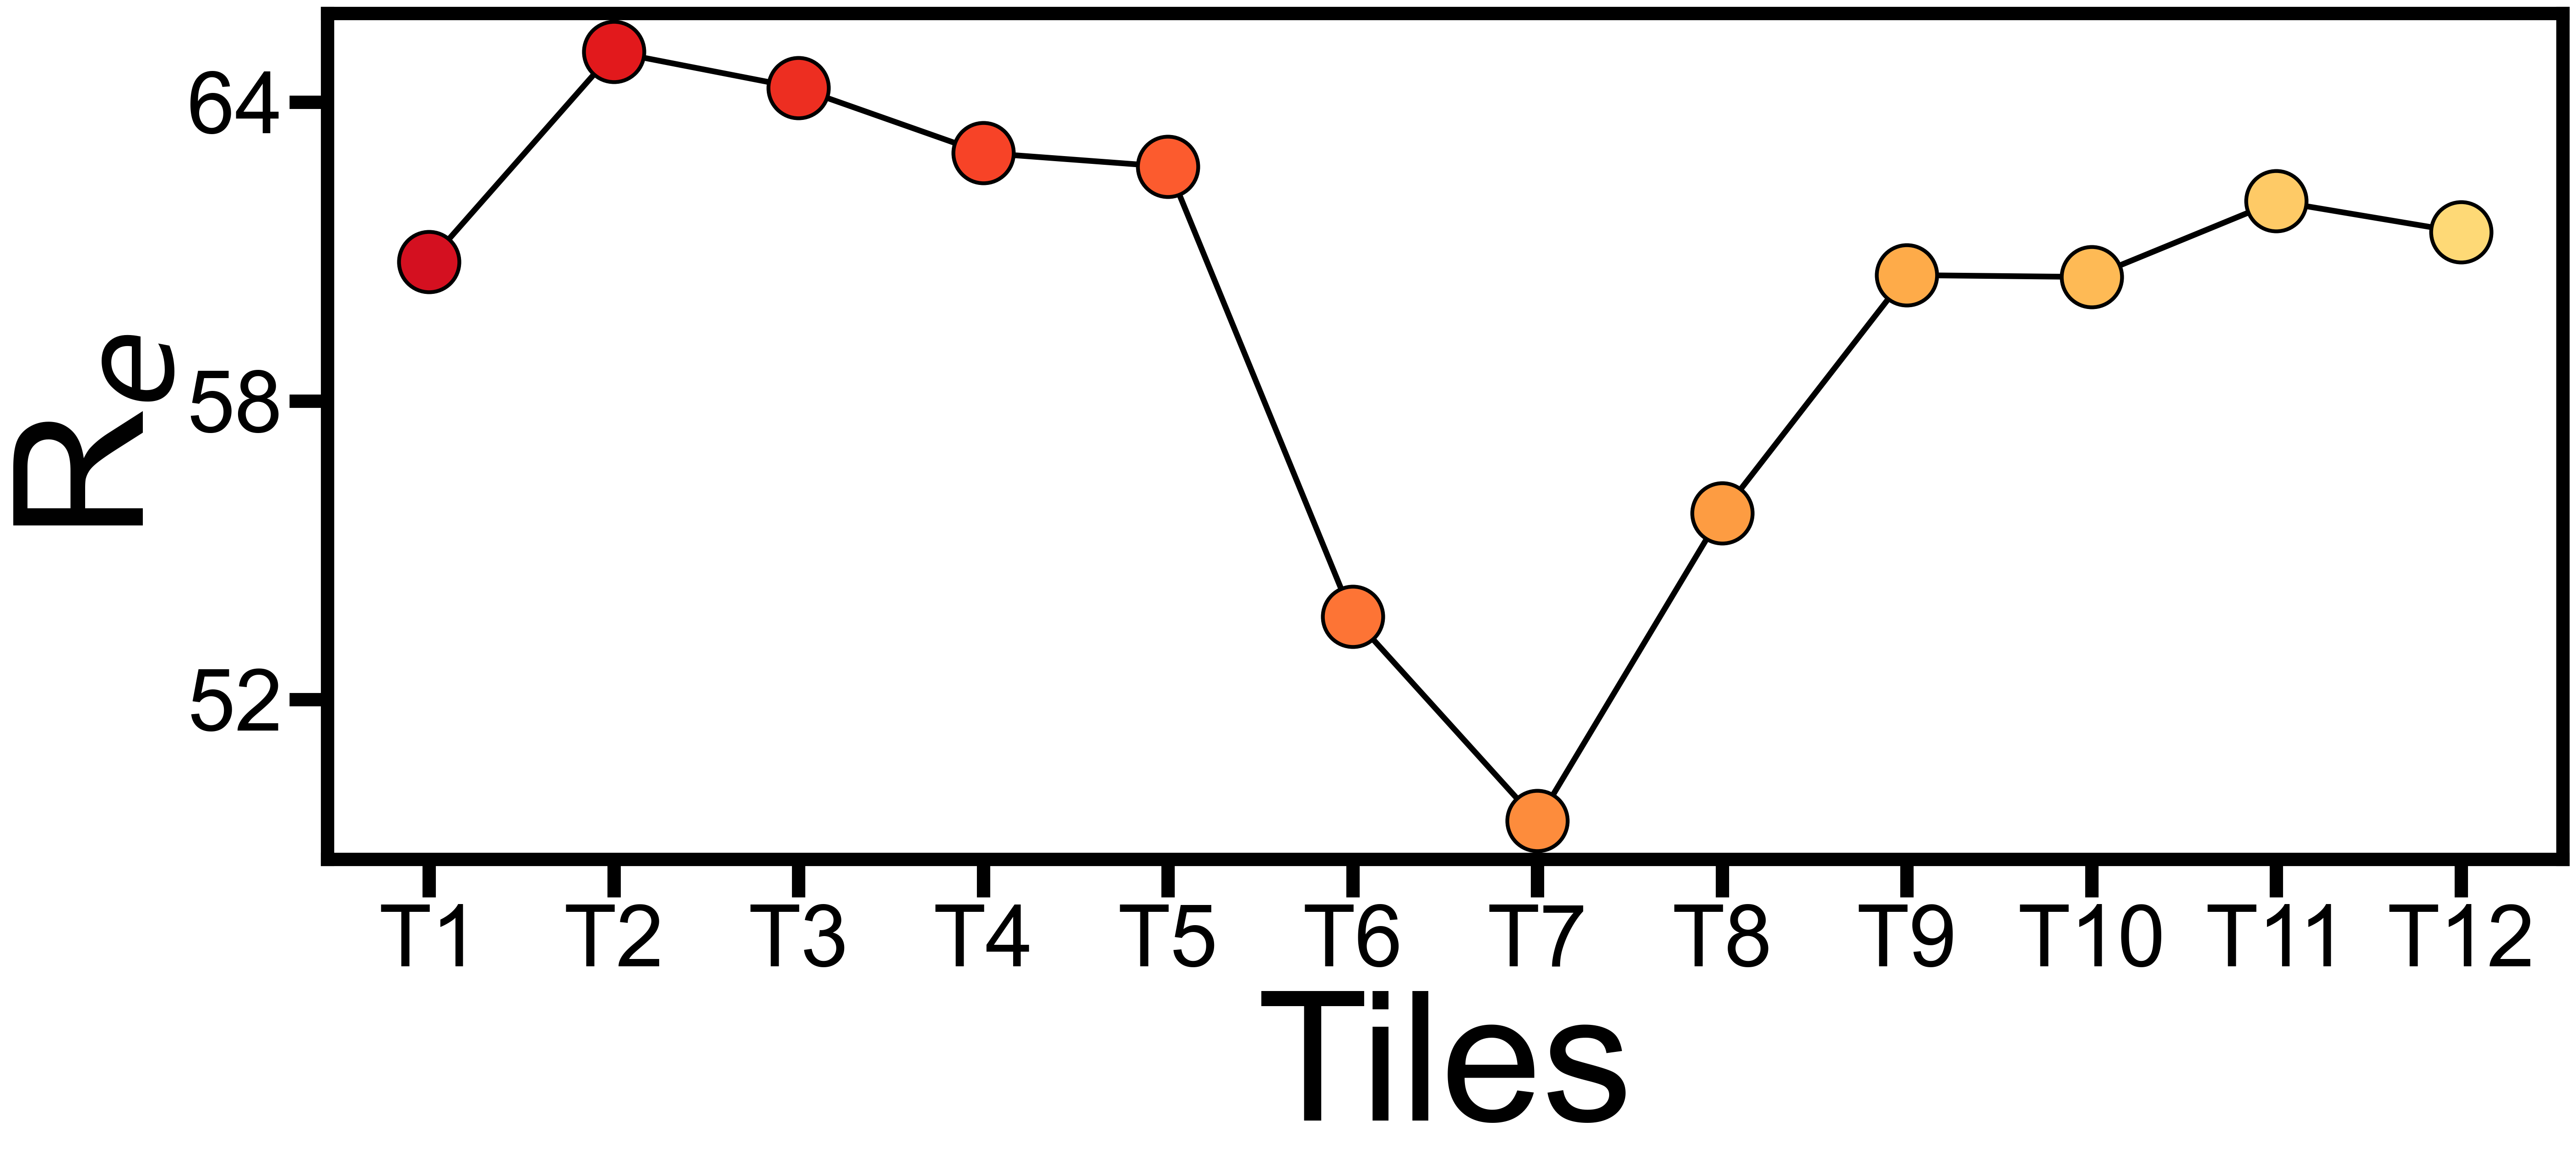

In [15]:
#Relative end-to-end distance

fig, ax = plt.subplots(figsize=(21, 8))

N=12
plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.YlOrRd(np.linspace(0.8, 0.25, N)))

xticks = []
xticks_labels = []
for i in range(12):
    pos = i+1
    xticks.append(pos)
    xticks_labels.append('T'+str(pos))
print(xticks)

x_pos =[]
y_pos = []
for i, e in tile_df.iterrows():
    s= 1000
    pos = i +1
    re = e['R_end_to_end']
    ax.scatter(pos, re, s=s, edgecolor='k', linewidth=2, zorder=3)
    if pos == 1:
        x_pos.append(pos)
        y_pos.append(re)
    else:
        x_pos.append(pos)
        y_pos.append(re)
        ax.plot(x_pos, y_pos, 'k', linewidth=3, zorder=1)
        x_pos = [x_pos[-1]]
        y_pos = [y_pos[-1]]

fontsize=45
yticks= [52, 58, 64]
ax.set_yticks(yticks)
ax.set_yticklabels(yticks, fontsize= fontsize)

ax.set_xticks(xticks)
ax.set_xticklabels(xticks_labels, fontsize=fontsize)

label_size = "xx-large"
ax.set_ylabel('R$_e$', fontsize=label_size)
ax.set_xlabel('Tiles', fontsize=label_size)
#plt.savefig(r'End_to_end_distance_tiles.svg' , format='svg', bbox_inches='tight')

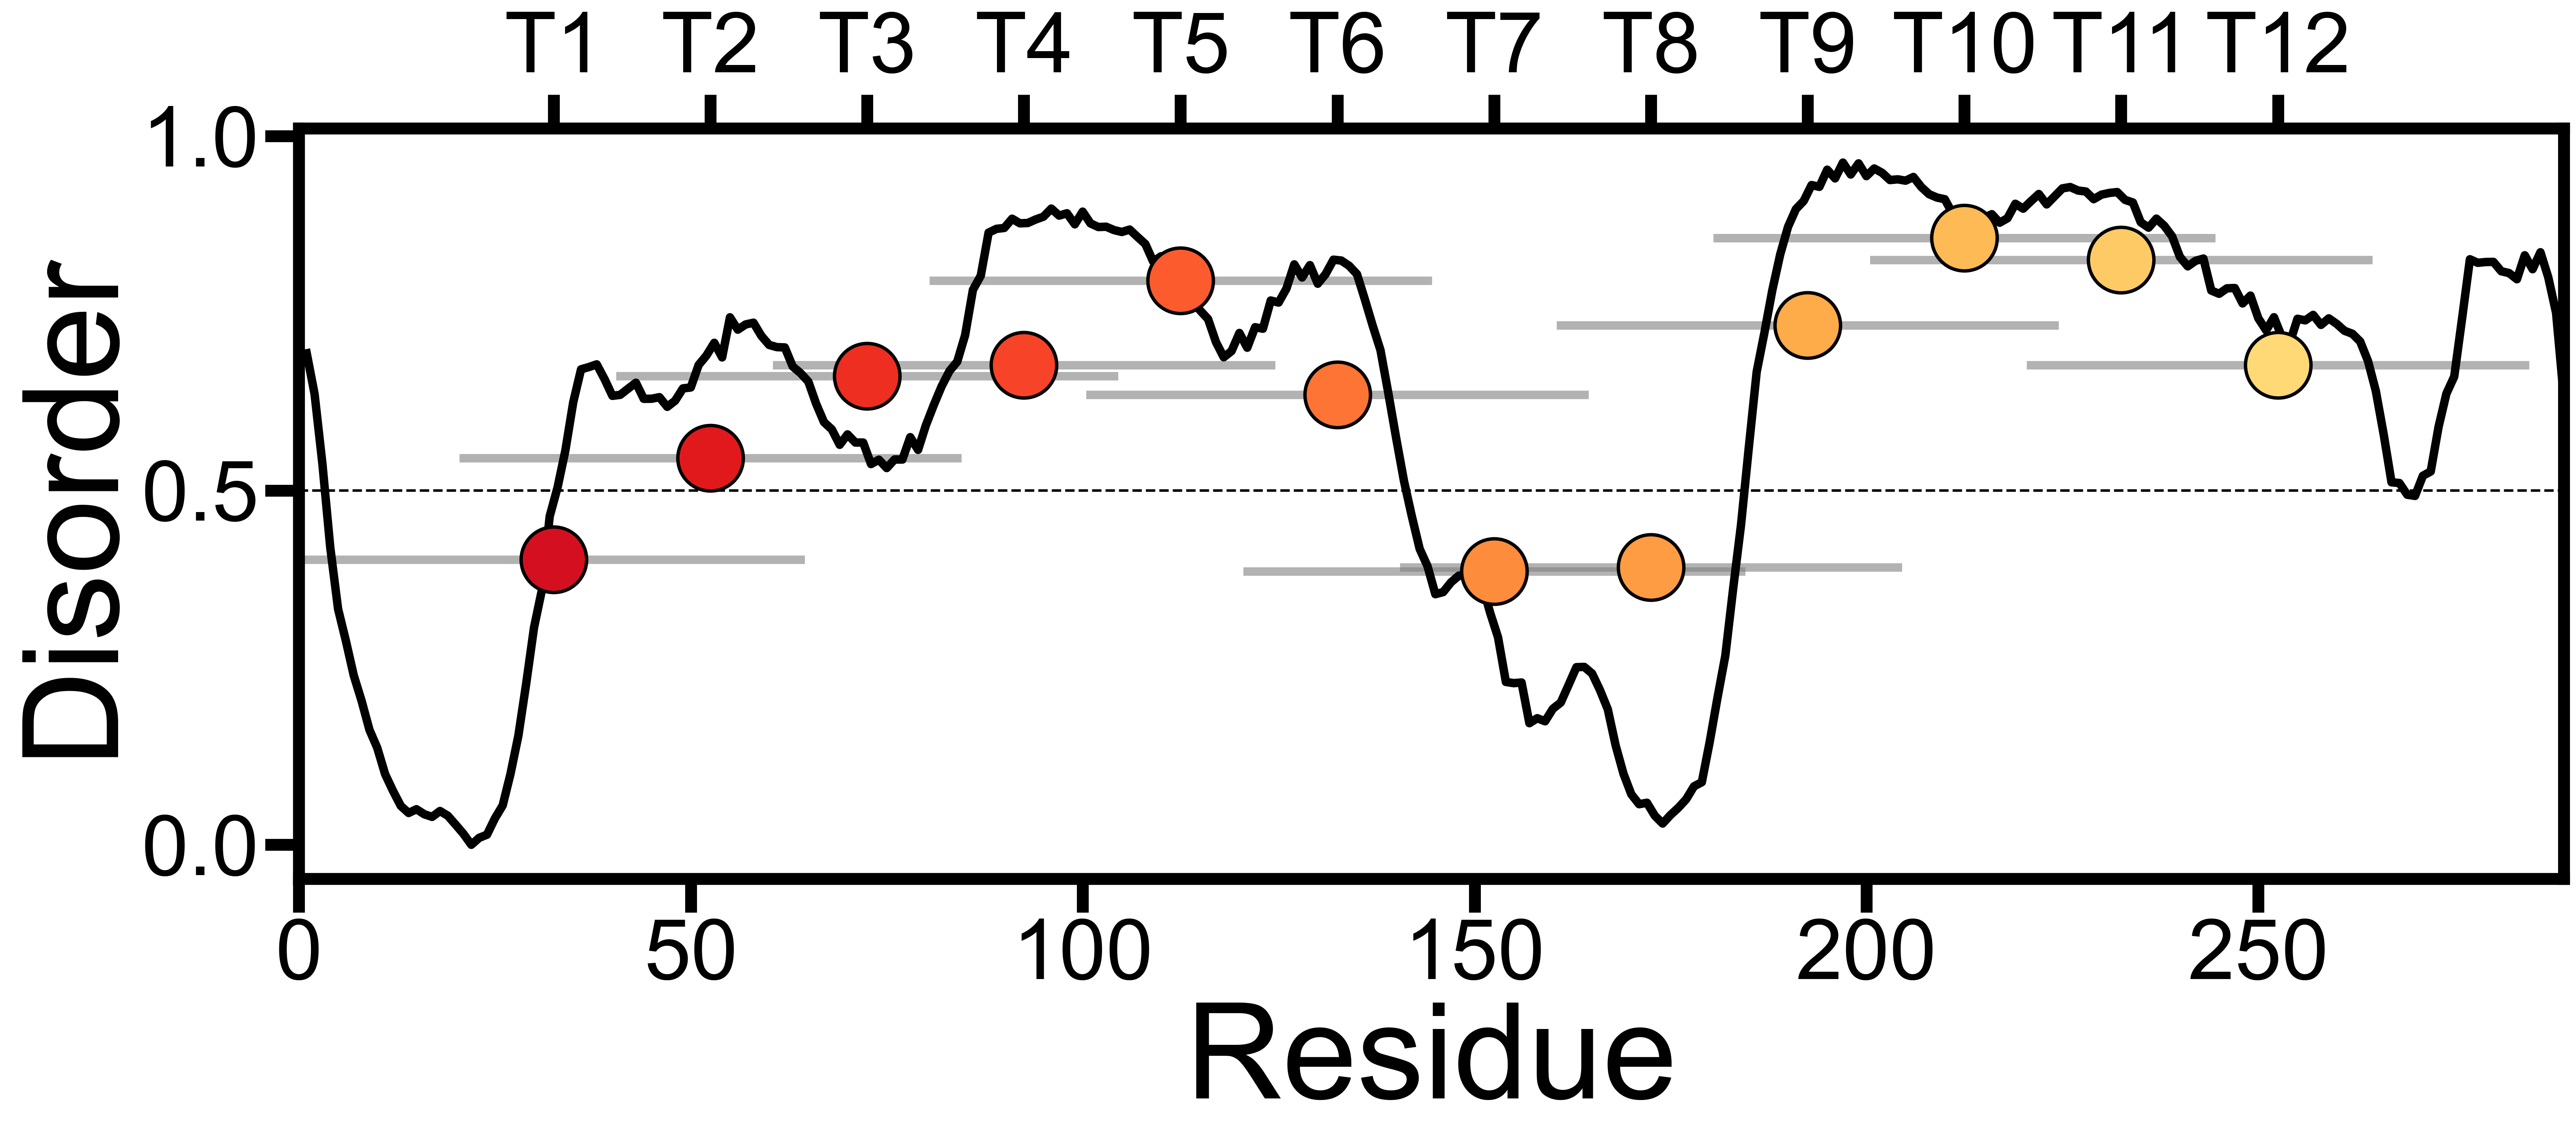

In [22]:
#Disorder

N=12
plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.YlOrRd(np.linspace(0.8, 0.25, N)))
fig, ax = plt.subplots(figsize=(24, 8))


"""
for i, df_item in enumerate(generator):
    df = df_item[1]
    middle = df[' Index'].median() +20* i 
    avg = df[' Disorder'].mean()
    ax.scatter(middle, avg, marker='s', s=200, edgecolors='black')
"""    
Tile_sort_values = []

    
twin_xlabels = []
for i, row in tile_df.iterrows():
    middle = (row.iloc[1] + row.iloc[2])/2
    avg = row.iloc[9]
    start = row.iloc[1]
    end= row.iloc[2]
    
    ax.plot([start, end], [avg, avg], color='gray', linewidth=5, alpha=0.6)
    ax.scatter(middle, avg, s=1500, edgecolors='black', zorder=3, linewidth=2)
    twin_xlabels.append(middle)
    

e1a_x = np.linspace(1,289, 289)
ax.plot(e1a_x, e1a_full_length['disorder_array'][0], c='black', linewidth=5)
ax.set_xlabel(xlabel='Residue', fontsize='x-large')
ax.set_ylabel(ylabel='Disorder', fontsize='x-large')
#ax.text(5, 0.9, 'DISORDERED')
#ax.text(250, 0.1, 'ORDERED')
ax.axhline(0.5, linestyle='--', c='black')
# ax.imshow([[0.5, 0.5], [0, 300]], cmap=plt.cm.seismic)
xmin, xmax = xlim = 0, 290
ymin, ymax = ylim = 0, 1
#ax.imshow([[1, 1], [0, 0]], cmap=plt.cm.seismic, extent=(xmin, xmax, ymin, ymax), alpha=0.3, interpolation='bicubic')
ax.set_aspect('auto')
ax.set_xlim(0,289)

new_labels = [ "T"+str(i+1) for i in range(12)]
twin_ax = ax.twiny()
twin_ax.set_xticks(twin_xlabels)

twin_ax.set_xticklabels(new_labels)
#twin_ax.set_yticks([])
twin_ax.set_xlim(0,289)
#plt.savefig(r'disorder_plot_fulllength.svg', format='svg', bbox_inches='tight')

In [20]:
e1a_full_length['disorder_array']

0    [0.6935, 0.6361, 0.5376, 0.4197, 0.3327, 0.287...
Name: disorder_array, dtype: object